In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

In [2]:
df = pd.read_csv("flights.csv")



C:\Users\dicorio\AppData\Local\Temp\ipykernel_2444\819463170.py:1: DtypeWarning: Columns (7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("flights.csv")


In [3]:
df.shape

(5819079, 31)

In [16]:
df.head(100)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_DELAYED,ROUTE
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,0,ANC to SEA
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,0,LAX to PBI
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,0,SFO to CLT
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,0,LAX to MIA
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,0,SEA to ANC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,2015,1,1,4,EV,5498,N132EV,ORD,DTW,535,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,1,ORD to DTW
101,2015,1,1,4,OO,6512,N925SW,FAT,LAX,535,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,0,FAT to LAX
102,2015,1,1,4,UA,1577,N69813,SMF,DEN,538,...,0,0,NaN,22.0,0.0,56.0,0.0,0.0,1,SMF to DEN
103,2015,1,1,4,OO,4986,N719SK,AUS,LAX,538,...,0,0,NaN,0.0,0.0,0.0,0.0,0.0,0,AUS to LAX


In [47]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 32 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24

In [44]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24

In [4]:
pd.isnull(df).sum()

YEAR                         0
MONTH                        0
DAY                          0
DAY_OF_WEEK                  0
AIRLINE                      0
FLIGHT_NUMBER                0
TAIL_NUMBER              14721
ORIGIN_AIRPORT               0
DESTINATION_AIRPORT          0
SCHEDULED_DEPARTURE          0
DEPARTURE_TIME           86153
DEPARTURE_DELAY          86153
TAXI_OUT                 89047
WHEELS_OFF               89047
SCHEDULED_TIME               6
ELAPSED_TIME            105071
AIR_TIME                105071
DISTANCE                     0
WHEELS_ON                92513
TAXI_IN                  92513
SCHEDULED_ARRIVAL            0
ARRIVAL_TIME             92513
ARRIVAL_DELAY           105071
DIVERTED                     0
CANCELLED                    0
CANCELLATION_REASON    5729195
AIR_SYSTEM_DELAY       4755640
SECURITY_DELAY         4755640
AIRLINE_DELAY          4755640
LATE_AIRCRAFT_DELAY    4755640
WEATHER_DELAY          4755640
dtype: int64

In [13]:
print(df.describe())

            YEAR         MONTH           DAY   DAY_OF_WEEK  FLIGHT_NUMBER  \
count  5819079.0  5.819079e+06  5.819079e+06  5.819079e+06   5.819079e+06   
mean      2015.0  6.524085e+00  1.570459e+01  3.926941e+00   2.173093e+03   
std          0.0  3.405137e+00  8.783425e+00  1.988845e+00   1.757064e+03   
min       2015.0  1.000000e+00  1.000000e+00  1.000000e+00   1.000000e+00   
25%       2015.0  4.000000e+00  8.000000e+00  2.000000e+00   7.300000e+02   
50%       2015.0  7.000000e+00  1.600000e+01  4.000000e+00   1.690000e+03   
75%       2015.0  9.000000e+00  2.300000e+01  6.000000e+00   3.230000e+03   
max       2015.0  1.200000e+01  3.100000e+01  7.000000e+00   9.855000e+03   

       SCHEDULED_DEPARTURE  DEPARTURE_TIME  DEPARTURE_DELAY      TAXI_OUT  \
count         5.819079e+06    5.732926e+06     5.732926e+06  5.730032e+06   
mean          1.329602e+03    1.335204e+03     9.370158e+00  1.607166e+01   
std           4.837518e+02    4.964233e+02     3.708094e+01  8.895574e+00  

In [5]:
delay_cols = ['AIR_SYSTEM_DELAY','SECURITY_DELAY','AIRLINE_DELAY','LATE_AIRCRAFT_DELAY','WEATHER_DELAY']
df[delay_cols] = df[delay_cols].fillna(0)

In [6]:
df = df.dropna(subset=['DEPARTURE_DELAY'])

In [7]:
df.loc[:, 'IS_DELAYED'] = df['DEPARTURE_DELAY'].apply(lambda x: 1 if x > 0 else 0)

In [8]:
df.loc[:, 'ROUTE'] = df['ORIGIN_AIRPORT'].astype(str) + " to " + df['DESTINATION_AIRPORT'].astype(str)

In [9]:
df['IS_DELAYED'].mean() * 100

np.float64(37.077366775709294)

In [10]:
df['CANCELLED'].mean() * 100

np.float64(0.06508020511689842)

In [11]:
df.groupby('AIRLINE')['DEPARTURE_DELAY'].mean()

AIRLINE
AA     8.900856
AS     1.785801
B6    11.514353
DL     7.369254
EV     8.715934
F9    13.350858
HA     0.485713
MQ    10.125188
NK    15.944766
OO     7.801104
UA    14.435441
US     6.141137
VX     9.022595
WN    10.581986
Name: DEPARTURE_DELAY, dtype: float64

In [12]:
df.groupby('ROUTE')['DEPARTURE_DELAY'].mean()

ROUTE
10135 to 10397     5.931818
10135 to 11433    14.626667
10135 to 13930     8.171053
10136 to 11298     4.061856
10140 to 10397    -0.373626
                    ...    
XNA to SFO         6.352941
XNA to SLC       -10.000000
YAK to CDV        -2.426829
YAK to JNU       -10.145897
YUM to PHX         1.232470
Name: DEPARTURE_DELAY, Length: 8606, dtype: float64

In [13]:
df.groupby('MONTH')['DEPARTURE_DELAY'].mean()

MONTH
1      9.759471
2     11.885284
3      9.660903
4      7.721885
5      9.454144
6     13.986016
7     11.394664
8      9.932045
9      4.823560
10     4.982661
11     6.944197
12    11.783529
Name: DEPARTURE_DELAY, dtype: float64

In [14]:
df[delay_cols].sum()


AIR_SYSTEM_DELAY       14335762.0
SECURITY_DELAY            80985.0
AIRLINE_DELAY          20172956.0
LATE_AIRCRAFT_DELAY    24961931.0
WEATHER_DELAY           3100233.0
dtype: float64

In [15]:
airline_delay = df.groupby('AIRLINE')['DEPARTURE_DELAY'].mean().sort_values(ascending=False)

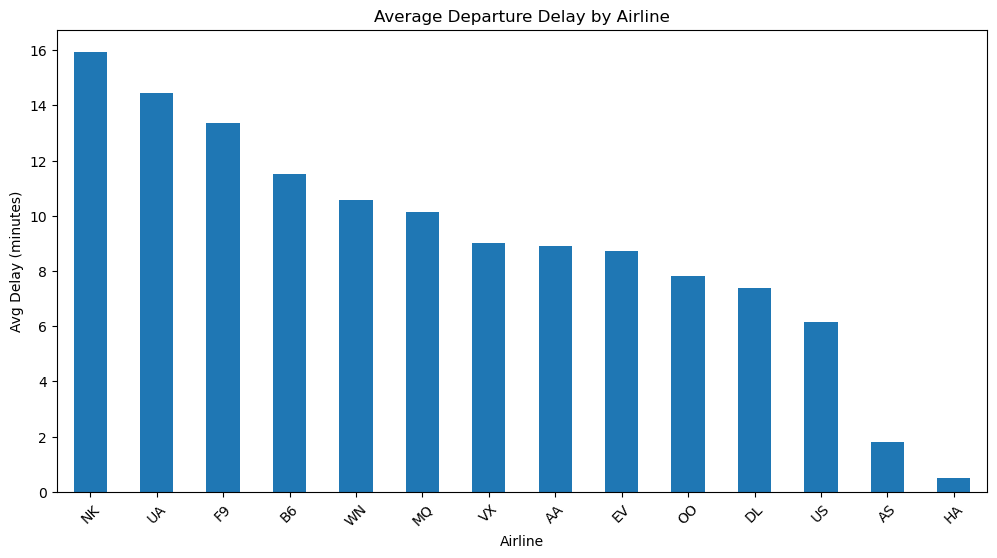

In [20]:
plt.figure(figsize=(12,6))
airline_delay.plot(kind='bar')
plt.title('Average Departure Delay by Airline')
plt.xlabel('Airline')
plt.ylabel('Avg Delay (minutes)')
plt.xticks(rotation=45)
plt.show()

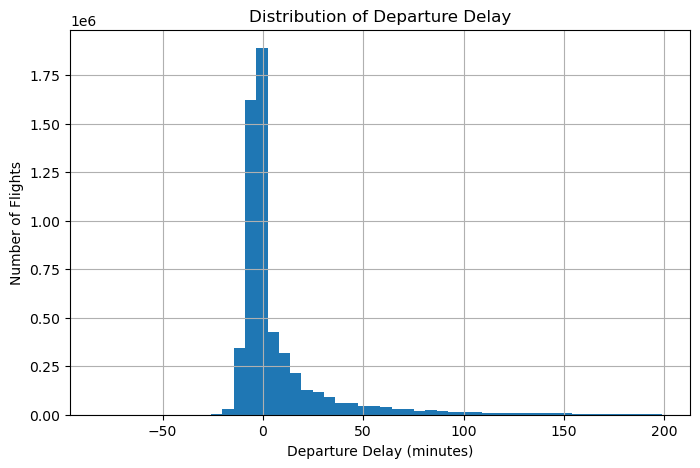

In [26]:
plt.figure(figsize=(8,5))

df[df['DEPARTURE_DELAY'] < 200]['DEPARTURE_DELAY'].hist(bins=50)

plt.title("Distribution of Departure Delay")
plt.xlabel("Departure Delay (minutes)")   
plt.ylabel("Number of Flights")           

plt.show()

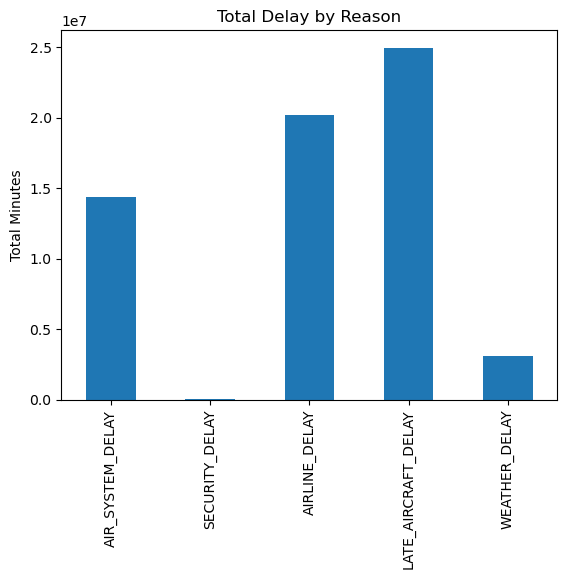

In [28]:
delay_cols = ['AIR_SYSTEM_DELAY','SECURITY_DELAY','AIRLINE_DELAY','LATE_AIRCRAFT_DELAY','WEATHER_DELAY']

df[delay_cols].sum().plot(kind='bar')
plt.title('Total Delay by Reason')
plt.ylabel('Total Minutes')
plt.show()

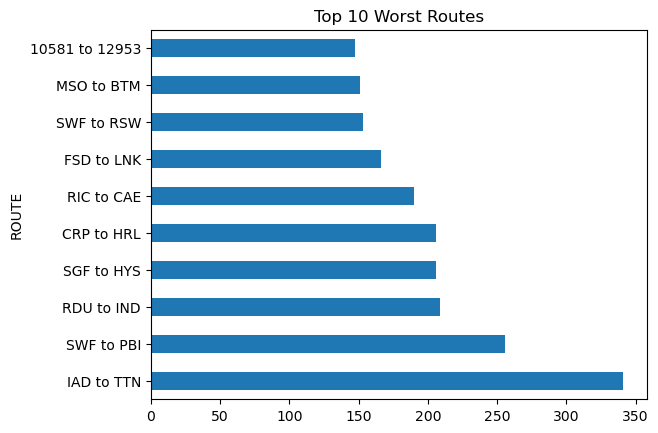

In [29]:
route_delay = df.groupby('ROUTE')['DEPARTURE_DELAY'].mean().sort_values(ascending=False).head(10)

route_delay.plot(kind='barh')
plt.title('Top 10 Worst Routes')
plt.show()